# E-commerce: анализ заказов Olist

В этом исследовании разбираю заказы Olist и выбираю, какие проблемы доставки
стоит проверять в первую очередь. Для контекста изучаю стоимость заказов
и покупки клиентов.

Результат должен быть пригоден для следующего шага: показать проблемный
период, направления доставки и конкретные заказы для разбора.
Постановка условная, реального заказчика у проекта нет.

Вопросы исследования:
1. Как устроены данные и что нужно проверить перед расчетами?
2. Как менялись заказы, покупатели и стоимость товаров?
3. Где стало больше опозданий и как изменились сроки доставки?
4. Сколько клиентов покупают повторно и что считать повторной покупкой?
5. Как возвращаются покупатели разных когорт?
6. Какие группы покупателей можно выделить по RFM?

In [1]:
import os

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted", rc={"grid.alpha": 0.2})
pd.set_option("display.max_columns", 12)

# Эти папки нужны для сохранения графиков и итоговых таблиц.
os.makedirs("assets", exist_ok=True)
os.makedirs("results", exist_ok=True)

## 1. Загрузка и проверка данных

Источник - [Brazilian E-Commerce Public Dataset by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce).
Использую версию 2, чтобы повторные запуски работали с теми же данными.

| Таблица | Что находится в одной строке |
|---|---|
| customers | Запись о покупателе для конкретного заказа |
| orders | Заказ |
| order_items | Товарная позиция заказа |

`customer_id` связывает заказ с записью в customers.
Покупателя в разных заказах определяю по `customer_unique_id`.
`price` - стоимость товарной позиции, `freight_value` - стоимость ее доставки.

In [2]:
customers_path = kagglehub.dataset_download(
    "olistbr/brazilian-ecommerce/versions/2",
    path="olist_customers_dataset.csv",
    output_dir="data/raw"
)

orders_path = kagglehub.dataset_download(
    "olistbr/brazilian-ecommerce/versions/2",
    path="olist_orders_dataset.csv",
    output_dir="data/raw"
)

items_path = kagglehub.dataset_download(
    "olistbr/brazilian-ecommerce/versions/2",
    path="olist_order_items_dataset.csv",
    output_dir="data/raw"
)

customers = pd.read_csv(customers_path)
orders = pd.read_csv(orders_path)
order_items = pd.read_csv(items_path)

In [3]:
data_overview = pd.DataFrame({
    "Строк": [len(customers), len(orders), len(order_items)],
    "Столбцов": [customers.shape[1], orders.shape[1], order_items.shape[1]]
}, index=["customers", "orders", "order_items"])

data_overview

,Строк,Столбцов
customers,99441,5
orders,99441,8
order_items,112650,7


In [4]:
# Даты нужны для отбора периода и расчета сроков доставки, сразу привожу их к нужному типу и формату
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for column in date_columns:
    orders[column] = pd.to_datetime(orders[column], format="%Y-%m-%d %H:%M:%S")

order_items["shipping_limit_date"] = pd.to_datetime(order_items["shipping_limit_date"])

In [5]:
# Количество повторов ключей
key_check = pd.Series({
    "Повторы customer_id в customers": customers["customer_id"].duplicated().sum(),
    "Повторы order_id в orders": orders["order_id"].duplicated().sum(),
    "Повторы customer_id в orders": orders["customer_id"].duplicated().sum(),
    "Повторы пары order_id + order_item_id": order_items.duplicated(["order_id", "order_item_id"]).sum()
}, name="Повторов")

key_check.to_frame()

,Повторов
Повторы customer_id в customers,0
Повторы order_id в orders,0
Повторы customer_id в orders,0
Повторы пары order_id + order_item_id,0


In [6]:
# Количество пропусков ключей
missing_keys = pd.Series({
    "customer_id в customers": customers["customer_id"].isna().sum(),
    "customer_unique_id": customers["customer_unique_id"].isna().sum(),
    "order_id в orders": orders["order_id"].isna().sum(),
    "customer_id в orders": orders["customer_id"].isna().sum(),
    "order_id в order_items": order_items["order_id"].isna().sum(),
    "order_item_id": order_items["order_item_id"].isna().sum()
}, name="Пропусков")

missing_keys.to_frame()

,Пропусков
customer_id в customers,0
customer_unique_id,0
order_id в orders,0
customer_id в orders,0
order_id в order_items,0
order_item_id,0


In [7]:
# Сверяю связи таблиц до объединения
orders_have_customer = orders["customer_id"].isin(customers["customer_id"])
items_have_order = order_items["order_id"].isin(orders["order_id"])
orders_have_items = orders["order_id"].isin(order_items["order_id"])

link_check = pd.Series({
    "Заказы без покупателя": (~orders_have_customer).sum(),
    "Позиции без заказа": (~items_have_order).sum(),
    "Заказы без товарных позиций": (~orders_have_items).sum()
}, name="Записей")

link_check.to_frame()

,Записей
Заказы без покупателя,0
Позиции без заказа,0
Заказы без товарных позиций,775


In [8]:
# Распределение статусов заказов, у которых нет товарных позиций
orders.loc[~orders_have_items, "order_status"].value_counts().to_frame("Без позиций")

,Без позиций
order_status,
unavailable,603
canceled,164
created,5
invoiced,2
shipped,1


In [9]:
# Отдельно проверяю деньги: пропуски и отрицательные значения
money_check = pd.DataFrame({
    "Пропусков": order_items[["price", "freight_value"]].isna().sum(),
    "Отрицательных значений": (order_items[["price", "freight_value"]] < 0).sum()
})

money_check

,Пропусков,Отрицательных значений
price,0,0
freight_value,0,0


Ключи не повторяются, потерянных ссылок между таблицами нет.
У 775 заказов нет позиций. В основном это `unavailable` и `canceled`.
Сохраню такие заказы для анализа статусов, а стоимость оставлю пропущенной.

Перед объединением сложу позиции до уровня заказа.
Иначе заказ с несколькими товарами можно ошибочно посчитать как несколько покупок.

In [10]:
order_totals = order_items.groupby("order_id", as_index=False).agg(
    item_count=("order_item_id", "size"),
    items_value=("price", "sum"),
    freight_value=("freight_value", "sum")
)

order_totals.head()

,order_id,item_count,items_value,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,199.90,18.14


In [11]:
# Сначала добавляю постоянный идентификатор покупателя и штат получения.
orders_with_customers = orders.merge(
    customers[["customer_id", "customer_unique_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Затем добавляю суммы и число позиций. Одна строка остается одним заказом.
orders_enriched = orders_with_customers.merge(
    order_totals,
    on="order_id",
    how="left",
    validate="one_to_one"
)

In [12]:
merge_check = pd.DataFrame({
    "До объединения": [
        len(orders), orders["order_id"].nunique(), len(order_items),
        order_items["price"].sum(), order_items["freight_value"].sum()
    ],
    "После объединения": [
        len(orders_enriched), orders_enriched["order_id"].nunique(),
        orders_enriched["item_count"].sum(),
        orders_enriched["items_value"].sum(), orders_enriched["freight_value"].sum()
    ]
}, index=["Заказы", "Разные order_id", "Товарные позиции", "Стоимость товаров", "Стоимость доставки"])

merge_check["Разница"] = merge_check["После объединения"] - merge_check["До объединения"]
merge_check.round(2)

,До объединения,После объединения,Разница
Заказы,99441.00,99441.00,0.0
Разные order_id,99441.00,99441.00,0.0
Товарные позиции,112650.00,112650.00,0.0
Стоимость товаров,13591643.70,13591643.70,0.0
Стоимость доставки,2251909.54,2251909.54,0.0


Число заказов, позиции и денежные суммы сохранились.
Завершенной покупкой далее считаю `delivered`.
Месяц покупки определяется датой оформления заказа, а не получения.
Статусы показывают состояние на момент выгрузки, история переходов неизвестна.

In [13]:
# Распределения статусов заказов
status_summary = orders_enriched["order_status"].value_counts().to_frame("Заказов")
status_summary["Доля, %"] = status_summary["Заказов"] / len(orders_enriched) * 100

status_summary.round(2)

,Заказов,"Доля, %"
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


In [14]:
completed_orders = orders_enriched.loc[orders_enriched["order_status"] == "delivered"].copy()

date_quality = pd.Series({
    "Без даты получения": completed_orders["order_delivered_customer_date"].isna().sum(),
    "Передача раньше оформления": (
        completed_orders["order_delivered_carrier_date"] < completed_orders["order_purchase_timestamp"]
    ).sum(),
    "Получение раньше передачи": (
        completed_orders["order_delivered_customer_date"] < completed_orders["order_delivered_carrier_date"]
    ).sum(),
    "Без стоимости товаров": completed_orders["items_value"].isna().sum()
}, name="Доставленных заказов")

date_quality.to_frame()

,Доставленных заказов
Без даты получения,8
Передача раньше оформления,165
Получение раньше передачи,23
Без стоимости товаров,0


In [15]:
monthly_coverage = pd.DataFrame({
    "Все заказы": orders_enriched.resample("MS", on="order_purchase_timestamp")["order_id"].nunique(),
    "Доставленные": completed_orders.resample("MS", on="order_purchase_timestamp")["order_id"].nunique()
})

monthly_coverage.fillna(0).astype(int)

,Все заказы,Доставленные
order_purchase_timestamp,,
2016-09-01,4,1
2016-10-01,324,265
2016-11-01,0,0
2016-12-01,1,1
2017-01-01,800,750
2017-02-01,1780,1653
2017-03-01,2682,2546
2017-04-01,2404,2303
2017-05-01,3700,3546


Основной период - январь 2017 - июль 2018. Записи 2016 года разрежены,
а последняя завершенная покупка оформлена 29 августа 2018 года.
Поэтому август не использую как полный месяц. Более раннюю историю сохраню
для определения первых наблюдаемых покупок.

In [16]:
analysis_start = pd.Timestamp("2017-01-01")
analysis_end = pd.Timestamp("2018-08-01")

# Верхняя граница исключительная. Так учитывается весь последний день июля
in_period = (
    (completed_orders["order_purchase_timestamp"] >= analysis_start)
    & (completed_orders["order_purchase_timestamp"] < analysis_end)
)
analysis_orders = completed_orders.loc[in_period].copy()

## 2. Заказы и стоимость товаров

Оценю масштаб заказов и месячную динамику. Денежные показатели считаются
без доставки, в бразильских реалах (BRL).

In [17]:
monthly_metrics = analysis_orders.resample("MS", on="order_purchase_timestamp").agg(
    orders=("order_id", "nunique"),
    buyers=("customer_unique_id", "nunique"),
    items_value=("items_value", "sum"),
    mean_value=("items_value", "mean"),
    median_value=("items_value", "median")
)

period_metrics = pd.Series({
    "Завершенных заказов": analysis_orders["order_id"].nunique(),
    "Покупателей": analysis_orders["customer_unique_id"].nunique(),
    "Стоимость товаров, BRL": analysis_orders["items_value"].sum(),
    "Средняя стоимость товаров в заказе, BRL": analysis_orders["items_value"].mean(),
    "Медианная стоимость, BRL": analysis_orders["items_value"].median()
})

period_metrics.round(2).to_frame("Значение")

,Значение
Завершенных заказов,89860.00
Покупателей,86960.00
"Стоимость товаров, BRL",12342450.49
"Средняя стоимость товаров в заказе, BRL",137.35
"Медианная стоимость, BRL",86.99


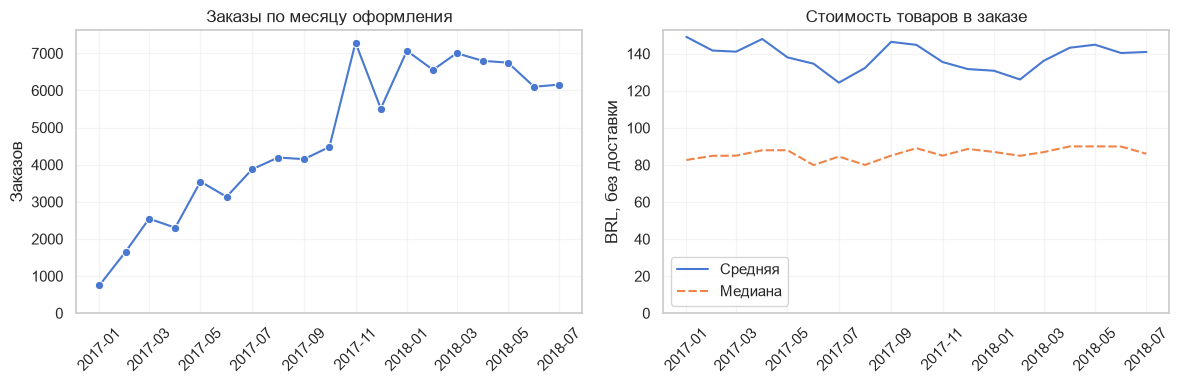

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.lineplot(data=monthly_metrics, x=monthly_metrics.index, y="orders", marker="o", ax=axes[0])
axes[0].set(title="Заказы по месяцу оформления", ylabel="Заказов", xlabel="", ylim=(0, None))

monthly_values = monthly_metrics[["mean_value", "median_value"]].rename(
    columns={"mean_value": "Средняя", "median_value": "Медиана"}
)
sns.lineplot(data=monthly_values, ax=axes[1])
axes[1].set(title="Стоимость товаров в заказе", ylabel="BRL, без доставки", xlabel="", ylim=(0, None))

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig("assets/orders_overview.png", dpi=150)
plt.show()

In [19]:
# На левом графике количество заказов в ноябре существенно больше, 
# чем в октябре. Определю разницу количественно 
comparison_columns = ["orders", "items_value", "mean_value"]
november = monthly_metrics.loc["2017-11-01", comparison_columns]
october = monthly_metrics.loc["2017-10-01", comparison_columns]
november_change = (november / october - 1) * 100

november_change.round(2).to_frame("Ноябрь к октябрю, %")

,"Ноябрь к октябрю, %"
orders,62.77
items_value,52.37
mean_value,-6.39


В рабочем периоде 89 860 заказов от 86 960 покупателей, стоимость товаров -
12,34 млн BRL. В ноябре 2017 года число заказов выросло на 62,77% к октябрю,
а общая стоимость товаров - на 52,37%, хотя средняя сумма заказа снизилась.
Для планирования нагрузки важно число заказов. Само снижение среднего чека
еще не означает ухудшения экономического результата.

In [20]:
# Дорогие заказы
p99 = analysis_orders["items_value"].quantile(0.99)
expensive = analysis_orders["items_value"] > p99

value_summary = pd.Series({
    "P90 стоимости, BRL": analysis_orders["items_value"].quantile(0.90),
    "P99 стоимости, BRL": p99,
    "Заказов дороже P99, %": expensive.mean() * 100,
    "Их доля стоимости товаров, %": (
        analysis_orders.loc[expensive, "items_value"].sum()
        / analysis_orders["items_value"].sum() * 100
    ),
    "Среднее без заказов дороже P99, BRL": analysis_orders.loc[~expensive, "items_value"].mean()
})

value_summary.round(2).to_frame("Значение")

,Значение
"P90 стоимости, BRL",269.90
"P99 стоимости, BRL",990.00
"Заказов дороже P99, %",1.00
"Их доля стоимости товаров, %",11.47
"Среднее без заказов дороже P99, BRL",122.82


In [21]:
# Проверяю, из чего сложился самый дорогой заказ
largest_order = analysis_orders.nlargest(1, "items_value").iloc[0]
largest_items = order_items.loc[order_items["order_id"] == largest_order["order_id"]]

largest_items[["order_item_id", "price", "freight_value"]]

,order_item_id,price,freight_value
1647,1,1680.0,28.01
1648,2,1680.0,28.01
1649,3,1680.0,28.01
1650,4,1680.0,28.01
1651,5,1680.0,28.01
1652,6,1680.0,28.01
1653,7,1680.0,28.01
1654,8,1680.0,28.01


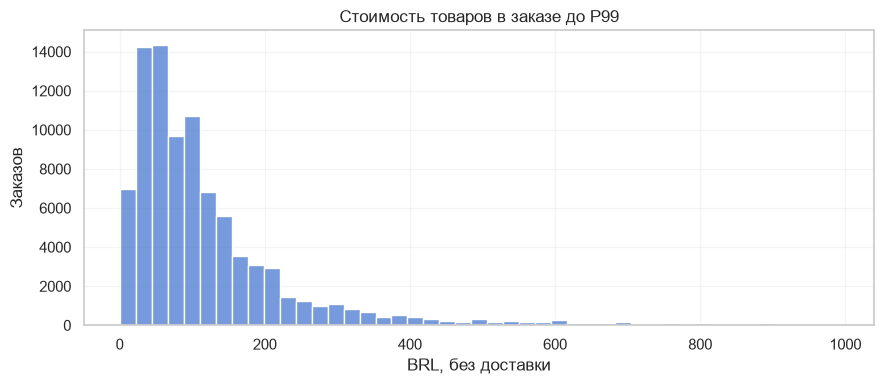

In [22]:
# График стоимости заказов (без учета доставки)
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=analysis_orders.loc[~expensive], x="items_value", bins=45, ax=ax)
ax.set(title="Стоимость товаров в заказе до P99", xlabel="BRL, без доставки", ylabel="Заказов")

fig.tight_layout()
fig.savefig("assets/order_values.png", dpi=150)
plt.show()

Около 1% дорогих заказов дают 11,47% общей стоимости товаров.
Максимальный заказ на 13 440 BRL состоит из восьми позиций по 1 680 BRL.
Его сумма согласуется с исходными записями. Оснований удалять его только
из-за высокой цены нет. Крупные заказы оставлены в итогах, P99 ограничивает
только график и отдельный расчет среднего для сравнения.

## 3. Где возникают проблемы доставки

Общий срок считаю от оформления до получения. Заказ опоздал, если его получили
позже обещанного календарного дня. Получение в обещанный день считается своевременным.

Вместе с опозданиями покажу P90 срока: за это время доставлены примерно 90% заказов.
Это важно, поскольку удлинение обещанного срока улучшит долю своевременных заказов,
но не сделает саму доставку быстрее.

In [23]:
# Для общего срока нужны обе даты и правильный порядок событий
has_delivery_date = analysis_orders["order_delivered_customer_date"].notna()
correct_delivery_order = (
    analysis_orders["order_delivered_customer_date"] >= analysis_orders["order_purchase_timestamp"]
)
delivery = analysis_orders.loc[has_delivery_date & correct_delivery_order].copy()

delivery["delivery_days"] = (
    delivery["order_delivered_customer_date"] - delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Для опоздания сравниваю календарные дни без времени суток
delivery["delay_days"] = (
    delivery["order_delivered_customer_date"].dt.normalize()
    - delivery["order_estimated_delivery_date"].dt.normalize()
).dt.days
delivery["is_late"] = delivery["delay_days"] > 0

In [24]:
delivery_summary = pd.Series({
    "Заказов в расчете": len(delivery),
    "Исключено по датам": len(analysis_orders) - len(delivery),
    "Медиана срока, дней": delivery["delivery_days"].median(),
    "P90 срока, дней": delivery["delivery_days"].quantile(0.90),
    "Опоздавших заказов": delivery["is_late"].sum(),
    "Доля опозданий, %": delivery["is_late"].mean() * 100
})

delivery_summary.round(2).to_frame("Значение")

,Значение
Заказов в расчете,89852.00
Исключено по датам,8.00
"Медиана срока, дней",10.62
"P90 срока, дней",23.61
Опоздавших заказов,6138.00
"Доля опозданий, %",6.83


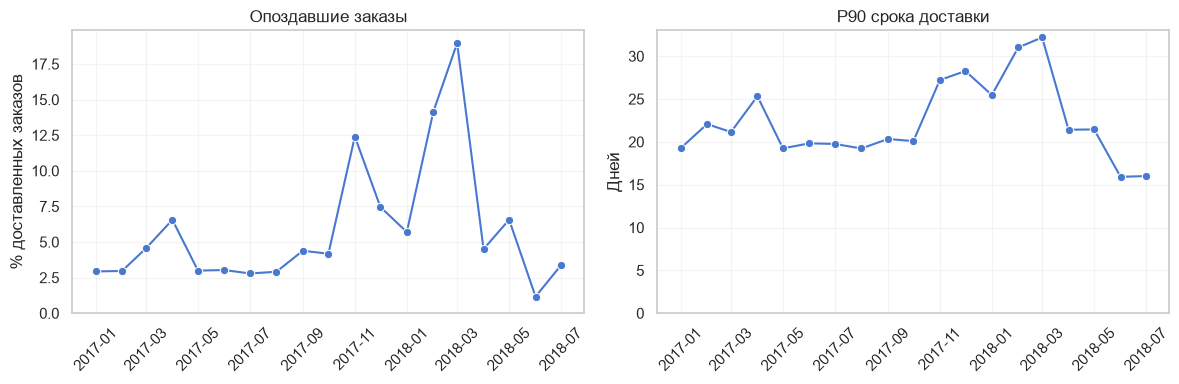

In [25]:
# Графики по нарушению сроков доставки
monthly_delivery = delivery.resample("MS", on="order_purchase_timestamp").agg(
    orders=("order_id", "nunique"),
    late_orders=("is_late", "sum"),
    late_rate=("is_late", "mean"),
    p90_days=("delivery_days", lambda values: values.quantile(0.90))
)
monthly_delivery["late_rate_pct"] = monthly_delivery["late_rate"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=monthly_delivery, x=monthly_delivery.index, y="late_rate_pct", marker="o", ax=axes[0])
axes[0].set(title="Опоздавшие заказы", ylabel="% доставленных заказов", xlabel="", ylim=(0, None))

sns.lineplot(data=monthly_delivery, x=monthly_delivery.index, y="p90_days", marker="o", ax=axes[1])
axes[1].set(title="P90 срока доставки", ylabel="Дней", xlabel="", ylim=(0, None))

for ax in axes:
    ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig("assets/delivery_overview.png", dpi=150)
plt.show()

В расчете 89 852 заказа. Восемь исключены из-за отсутствия даты получения.
Медиана доставки - 10,62 дня, P90 - 23,61 дня. Опоздали 6,83% заказов.

Подробно разберу март 2018 года: в нем самая высокая доля опозданий, 18,96%.
Сравню его с тремя предыдущими месяцами, декабрем-февралем.
Проверю также, насколько результат зависит от длины периода сравнения.

In [26]:
focus_month = monthly_delivery["late_rate"].idxmax()
focus_end = focus_month + pd.DateOffset(months=1)
baseline_start = focus_month - pd.DateOffset(months=3)

# Заказы трех предыдущих месяцев
in_previous_months = (
    (delivery["order_purchase_timestamp"] >= baseline_start)
    & (delivery["order_purchase_timestamp"] < focus_month)
)
baseline = delivery.loc[in_previous_months].copy()

# Заказы выбранного месяца
in_march = (
    (delivery["order_purchase_timestamp"] >= focus_month)
    & (delivery["order_purchase_timestamp"] < focus_end)
)
focus = delivery.loc[in_march].copy()
baseline_rate = baseline["is_late"].mean()
focus_rate = focus["is_late"].mean()

In [27]:
period_comparison = pd.DataFrame({
    "Заказов": [len(baseline), len(focus)],
    "Опоздали": [baseline["is_late"].sum(), focus["is_late"].sum()],
    "Опоздания, %": [baseline_rate * 100, focus_rate * 100]
}, index=["Декабрь-февраль", "Март"])

period_comparison.round(2)

,Заказов,Опоздали,"Опоздания, %"
Декабрь-февраль,19137,1740,9.09
Март,7003,1328,18.96


In [28]:
# Пересчитываю сравнение для нескольких предыдущих периодов
sensitivity_rows = []
for months in [1, 2, 3, 6]:
    start_date = focus_month - pd.DateOffset(months=months)
    in_previous_period = (
        (delivery["order_purchase_timestamp"] >= start_date)
        & (delivery["order_purchase_timestamp"] < focus_month)
    )
    previous = delivery.loc[in_previous_period]
    previous_rate = previous["is_late"].mean()
    sensitivity_rows.append({
        "Предыдущих месяцев": months,
        "Заказов": len(previous),
        "Опоздания раньше, %": previous_rate * 100,
        "Разница с мартом, п.п.": (focus_rate - previous_rate) * 100
    })

baseline_sensitivity = pd.DataFrame(sensitivity_rows).set_index("Предыдущих месяцев")
baseline_sensitivity.round(2)

,Заказов,"Опоздания раньше, %","Разница с мартом, п.п."
Предыдущих месяцев,,,
1,6555,14.13,4.84
2,13624,9.75,9.21
3,19137,9.09,9.87
6,35053,8.60,10.37


Относительно декабря-февраля доля опозданий выросла на 9,87 п.п.
Рост виден и при других периодах сравнения, хотя его величина меняется.
Сезонность этим сравнением не устранена.

Могло ли опозданий стать больше потому, что заказы чаще стали отправлять
в штаты, где доставка и раньше опаздывала? Для проверки возьму долю
опозданий каждого штата за декабрь-февраль и применю ее к мартовским заказам.

In [29]:
# Считаю показатели по каждому штату отдельно для двух периодов
previous_states = baseline.groupby("customer_state").agg(
    baseline_orders=("order_id", "nunique"),
    baseline_late=("is_late", "sum"),
    baseline_rate=("is_late", "mean")
)
march_states = focus.groupby("customer_state").agg(
    focus_orders=("order_id", "nunique"),
    focus_late=("is_late", "sum"),
    focus_rate=("is_late", "mean")
)
state_comparison = previous_states.join(march_states, how="outer")

In [30]:
# Все штаты должны присутствовать в обоих периодах для такого сравнения
state_coverage = state_comparison.isna().sum().to_frame("Штатов без значения")
state_coverage

,Штатов без значения
baseline_orders,0
baseline_late,0
baseline_rate,0
focus_orders,0
focus_late,0
focus_rate,0


In [31]:
# Сколько заказов опоздало бы в марте при прежней доле опозданий каждого штата
state_comparison["expected_late"] = (
    state_comparison["focus_orders"] * state_comparison["baseline_rate"]
)
state_comparison["excess_late"] = (
    state_comparison["focus_late"] - state_comparison["expected_late"]
)
standardized_rate = state_comparison["expected_late"].sum() / len(focus)

geo_check = pd.Series({
    "Декабрь-февраль, фактически": baseline_rate * 100,
    "Мартовские заказы при прежних долях по штатам": standardized_rate * 100,
    "Март, фактически": focus_rate * 100
}, name="Опоздания, %")

geo_check.round(2).to_frame()

,"Опоздания, %"
"Декабрь-февраль, фактически",9.09
Мартовские заказы при прежних долях по штатам,8.95
"Март, фактически",18.96


Например, в SP за декабрь-февраль опоздали 4,64% заказов.
Если применить эту долю к 2 971 мартовскому заказу, получится около 138 опозданий.
Фактически их было 280. Разница - около 142 заказов.

Для всех штатов вместе такой расчет дает 8,95%, почти столько же, сколько
9,09% за предыдущие месяцы. Фактические 18,96% этим не объясняются.
Внутри штатов также могли измениться товары, продавцы и условия доставки.

Дальше отсортирую штаты по разнице между фактическим и расчетным числом опозданий.
Это поможет выбрать направления для первого разбора, но не покажет,
сколько опозданий действительно можно было предотвратить.

In [32]:
state_comparison = state_comparison.sort_values("excess_late", ascending=False)
top_states = state_comparison.head(8)

state_table = top_states[["focus_orders", "focus_late", "expected_late", "excess_late"]].rename(columns={
    "focus_orders": "Заказов в марте", "focus_late": "Опоздали",
    "expected_late": "По прежней доле", "excess_late": "Разница"
})
state_table["Раньше, %"] = top_states["baseline_rate"] * 100
state_table["В марте, %"] = top_states["focus_rate"] * 100

state_table.round(2)

,Заказов в марте,Опоздали,По прежней доле,Разница,"Раньше, %","В марте, %"
customer_state,,,,,,
SP,2971,280,137.98,142.02,4.64,9.42
MG,856,175,42.71,132.29,4.99,20.44
RJ,864,298,205.61,92.39,23.80,34.49
BA,235,74,29.75,44.25,12.66,31.49
ES,133,55,12.90,42.10,9.70,41.35
RS,407,78,42.80,35.20,10.52,19.16
PR,369,49,18.72,30.28,5.07,13.28
CE,93,47,18.60,28.40,20.00,50.54


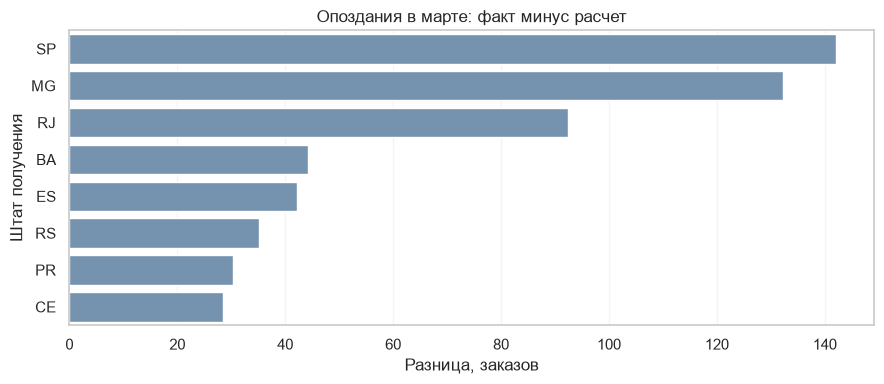

In [33]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=top_states.reset_index(), x="excess_late", y="customer_state", color="#6B92B9", ax=ax)
ax.set(title="Опоздания в марте: факт минус расчет", xlabel="Разница, заказов", ylabel="Штат получения")

fig.tight_layout()
fig.savefig("assets/delay_priorities.png", dpi=150)
plt.show()

In [34]:
priority_states = state_comparison.head(3).index.tolist()
priority_excess = state_comparison.loc[priority_states, "excess_late"].sum()
total_excess = state_comparison["excess_late"].sum()
priority_excess_share = priority_excess / total_excess * 100

Первые направления для проверки - SP (Сан-Паулу), MG (Минас-Жерайс)
и RJ (Рио-де-Жанейро). Вместе они дают 52,29% общей расчетной разницы.
В SP сравнительно небольшая доля опозданий сочетается с большим числом заказов.
В RJ опоздания были частыми уже в предыдущие месяцы.

Теперь проверю, на каком этапе изменились сроки и не сократилось ли время,
которое обещали покупателю.

In [35]:
# Объединяю периоды с подписью, чтобы одинаково рассчитать этапы
stage_data = pd.concat([
    baseline.assign(period="Декабрь-февраль"),
    focus.assign(period="Март")
])

stage_data["dispatch_days"] = (
    stage_data["order_delivered_carrier_date"] - stage_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400
stage_data["transit_days"] = (
    stage_data["order_delivered_customer_date"] - stage_data["order_delivered_carrier_date"]
).dt.total_seconds() / 86400
stage_data["promised_days"] = (
    stage_data["order_estimated_delivery_date"].dt.normalize()
    - stage_data["order_purchase_timestamp"].dt.normalize()
).dt.days

correct_stages = (stage_data["dispatch_days"] >= 0) & (stage_data["transit_days"] >= 0)
valid_stages = stage_data.loc[correct_stages].copy()

In [36]:
stage_quality = pd.DataFrame({
    "Всего заказов": stage_data.groupby("period").size(),
    "Подходят для расчета этапов": valid_stages.groupby("period").size()
})
stage_quality["Исключено"] = stage_quality["Всего заказов"] - stage_quality["Подходят для расчета этапов"]

stage_quality

,Всего заказов,Подходят для расчета этапов,Исключено
period,,,
Декабрь-февраль,19137,19137,0
Март,7003,7003,0


In [37]:
stage_comparison = valid_stages.groupby("period").agg(
    dispatch_days=("dispatch_days", "mean"),
    transit_days=("transit_days", "mean"),
    delivery_days=("delivery_days", "mean"),
    p90_days=("delivery_days", lambda values: values.quantile(0.90)),
    promised_days=("promised_days", "mean")
).rename(columns={
    "dispatch_days": "Оформление → перевозчик, среднее",
    "transit_days": "Перевозчик → получение, среднее",
    "delivery_days": "Весь срок, среднее",
    "p90_days": "Весь срок, P90",
    "promised_days": "Обещанный срок, среднее"
}).T

stage_comparison.round(2)

period,Декабрь-февраль,Март
"Оформление → перевозчик, среднее",3.62,3.33
"Перевозчик → получение, среднее",11.82,12.97
"Весь срок, среднее",15.44,16.30
"Весь срок, P90",28.25,32.19
"Обещанный срок, среднее",26.73,22.67


В обоих периодах для разбора этапов подходят все заказы сравнения.
Среднее время до передачи перевозчику сократилось с 3,62 до 3,33 дня,
после передачи - выросло с 11,82 до 12,97 дня.
P90 общего срока увеличился с 28,25 до 32,19 дня: самые долгие доставки
стали занимать больше времени.

Одновременно средний обещанный срок сократился с 26,73 до 22,67 календарного дня.
Фактические этапы измерены в прошедших сутках, обещание - разностью календарных дат.
Для первого разбора выбираю доставку после передачи перевозчику
и реалистичность обещанных сроков на трех выделенных направлениях.
Причина изменения показателей пока не установлена.

In [38]:
# Сохраняю конкретные заказы, с которых можно начать разбор
in_priority_state = focus["customer_state"].isin(priority_states)
review_columns = [
    "order_id", "customer_state", "order_purchase_timestamp",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date", "delivery_days", "delay_days"
]
review_orders = focus.loc[in_priority_state & focus["is_late"], review_columns]
review_orders = review_orders.sort_values(["customer_state", "delay_days"], ascending=[True, False])

review_orders.to_csv("results/delivery_review.csv", index=False)
state_comparison.to_csv("results/state_delay_comparison.csv", index_label="customer_state")

review_orders.head()

,order_id,customer_state,order_purchase_timestamp,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,delay_days
89429,73e675969b9e5495c9d1c8d4b3b21e1e,MG,2018-03-02 18:09:36,2018-03-06 16:49:06,2018-05-07 15:09:58,2018-03-27,65.875255,41
27154,30ee51f86a9d676801e824efd4aad215,MG,2018-03-14 19:52:53,2018-03-16 19:23:08,2018-05-12 11:20:59,2018-04-05,58.644514,37
22390,a0bb89116fae61995bdade42a37fccba,MG,2018-03-08 12:49:21,2018-03-09 18:41:02,2018-05-03 04:52:09,2018-03-29,55.668611,35
98758,32fef9bb0f0402350b640eb6f13dbe09,MG,2018-03-07 06:46:21,2018-03-08 19:54:23,2018-05-03 00:39:55,2018-03-29,56.745532,35
61695,ed3646c08c3440dfcf19f92588bf1ff1,MG,2018-03-12 14:47:15,2018-03-16 19:14:02,2018-05-03 15:47:35,2018-04-03,52.041898,30


## 4. Повторные покупки

Сначала посчитаю покупателей с двумя и более заказами за рабочий период.
Затем сравню повторы в одинаковом окне: 30 суток после первой наблюдаемой покупки.
Отдельно проверю заказы спустя более суток после первого.
Несколько заказов подряд еще не обязательно означают возвращение в магазин.

In [39]:
customer_orders = analysis_orders.groupby("customer_unique_id").agg(
    orders=("order_id", "nunique"),
    first_in_period=("order_purchase_timestamp", "min"),
    last_in_period=("order_purchase_timestamp", "max")
)
repeat_buyers = customer_orders["orders"] >= 2

customer_orders["orders"].value_counts().sort_index().to_frame("Покупателей")

,Покупателей
orders,
1,84351
2,2399
3,168
4,24
5,9
6,4
7,3
9,1
12,1


In [40]:
# Сортирую заказы клиента по времени. При одинаковом времени использую order_id
sequence = analysis_orders.sort_values([
    "customer_unique_id", "order_purchase_timestamp", "order_id"
]).copy()
sequence["order_number"] = sequence.groupby("customer_unique_id").cumcount()
sequence["first_in_period"] = sequence.groupby("customer_unique_id")["order_purchase_timestamp"].transform("min")
sequence["gap_in_period"] = sequence["order_purchase_timestamp"] - sequence["first_in_period"]

# Нумерация начинается с нуля. Номер 1 соответствует второму заказу
second_gaps = sequence.loc[sequence["order_number"] == 1, "gap_in_period"]
second_within_day = (second_gaps <= pd.Timedelta(days=1)).sum()

pd.Series({
    "Покупатели с несколькими заказами": repeat_buyers.sum(),
    "Второй заказ в пределах суток": second_within_day
}, name="Покупателей").to_frame()

,Покупателей
Покупатели с несколькими заказами,2609
Второй заказ в пределах суток,835


In [41]:
# Первую покупку ищу во всей истории, чтобы не объявить старого покупателя новым
first_purchases = completed_orders.groupby("customer_unique_id")["order_purchase_timestamp"].min()
first_purchases = first_purchases.rename("first_purchase")

# В расчете должны быть полностью доступны все 30 суток после первой покупки
full_observation = (
    (first_purchases >= analysis_start)
    & (first_purchases + pd.Timedelta(days=30) < analysis_end)
)
eligible_first = first_purchases.loc[full_observation]

repeat_window = sequence.merge(
    eligible_first, left_on="customer_unique_id", right_index=True,
    how="inner", validate="many_to_one"
)
repeat_window["gap"] = repeat_window["order_purchase_timestamp"] - repeat_window["first_purchase"]

In [42]:
within_30_days = repeat_window["gap"] <= pd.Timedelta(days=30)
additional_order = repeat_window["order_number"] > 0
after_24_hours = repeat_window["gap"] > pd.Timedelta(days=1)

repeat_30d = repeat_window.loc[additional_order & within_30_days, "customer_unique_id"].nunique()
repeat_after_24h = repeat_window.loc[after_24_hours & within_30_days, "customer_unique_id"].nunique()

repeat_summary = pd.DataFrame({
    "Покупателей с повтором": [repeat_buyers.sum(), repeat_30d, repeat_after_24h],
    "Покупателей в знаменателе": [len(customer_orders), len(eligible_first), len(eligible_first)]
}, index=["Два заказа и более за рабочий период", "Дополнительный заказ за 30 суток", "Заказ спустя >24 ч и до 30 суток"])
repeat_summary["Доля, %"] = (
    repeat_summary["Покупателей с повтором"] / repeat_summary["Покупателей в знаменателе"] * 100
)

repeat_summary.round(2)

,Покупателей с повтором,Покупателей в знаменателе,"Доля, %"
Два заказа и более за рабочий период,2609,86960,3.00
Дополнительный заказ за 30 суток,1292,81155,1.59
Заказ спустя >24 ч и до 30 суток,507,81155,0.62


Несколько заказов сделали 3,00% покупателей. У 835 из 2 609 таких клиентов
второй заказ оформлен в пределах суток после первого.

При полном 30-дневном наблюдении дополнительный заказ есть у 1,59%
из 81 155 покупателей, а спустя более суток - у 0,62%.
Порог суток показывает чувствительность к определению повтора.
Он не доказывает, что короткие интервалы относятся к одной сессии.
Этих результатов недостаточно для массовой скидочной кампании.
Сначала стоит изучить, что покупают клиенты и когда им обычно нужен следующий заказ.

## 5. Покупательские когорты

Объединю клиентов по месяцу первой наблюдаемой завершенной покупки.
В каждом следующем месяце посчитаю долю клиентов когорты, сделавших заказ.
Календарный следующий месяц отличается от 30 суток после первой покупки.

In [43]:
cohort_orders = analysis_orders.merge(
    first_purchases, left_on="customer_unique_id", right_index=True,
    how="left", validate="many_to_one"
)
cohort_orders["cohort_month"] = cohort_orders["first_purchase"].dt.to_period("M")
cohort_orders["order_month"] = cohort_orders["order_purchase_timestamp"].dt.to_period("M")

first_month = analysis_start.to_period("M")
last_month = analysis_end.to_period("M") - 1
new_in_period = (
    (cohort_orders["cohort_month"] >= first_month)
    & (cohort_orders["cohort_month"] <= last_month)
)
cohort_orders = cohort_orders.loc[new_in_period].copy()

# Возраст когорты в календарных месяцах с учетом смены года
cohort_orders["age"] = (
    (cohort_orders["order_month"].dt.year - cohort_orders["cohort_month"].dt.year) * 12
    + cohort_orders["order_month"].dt.month - cohort_orders["cohort_month"].dt.month
)

In [44]:
cohort_counts = cohort_orders.groupby(["cohort_month", "age"])["customer_unique_id"].nunique().unstack("age")
months = pd.period_range(first_month, last_month, freq="M")
cohort_counts = cohort_counts.reindex(index=months, columns=range(len(months)))

# Нули ставлю только в доступных месяцах. Будущие периоды остаются пустыми
for cohort in months:
    last_age = (last_month.year - cohort.year) * 12 + last_month.month - cohort.month
    cohort_counts.loc[cohort, 0:last_age] = cohort_counts.loc[cohort, 0:last_age].fillna(0)

cohort_size = cohort_counts[0]
retention = cohort_counts.div(cohort_size, axis=0) * 100

In [45]:
cohort_check = pd.Series({
    "Покупатели с первой покупкой в рабочем периоде": cohort_orders["customer_unique_id"].nunique(),
    "Сумма размеров когорт": cohort_size.sum(),
    "Разница": cohort_size.sum() - cohort_orders["customer_unique_id"].nunique()
}, name="Покупателей")

cohort_check.to_frame()

,Покупателей
Покупатели с первой покупкой в рабочем периоде,86950.0
Сумма размеров когорт,86950.0
Разница,0.0


In [46]:
# Размеры когорт помогают читать проценты на карте
cohort_size.to_frame("Покупателей в начале")

,Покупателей в начале
2017-01,717.0
2017-02,1628.0
2017-03,2503.0
2017-04,2256.0
2017-05,3451.0
2017-06,3037.0
2017-07,3752.0
2017-08,4057.0
2017-09,4004.0
2017-10,4328.0


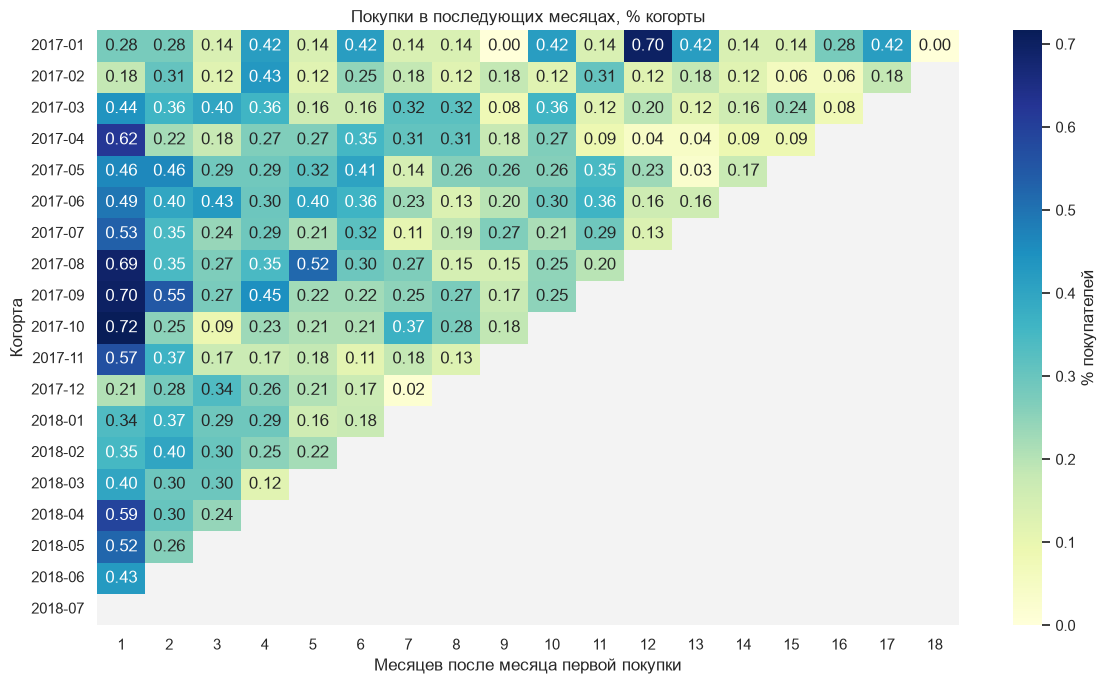

In [47]:
# Месяц 0 всегда равен 100%. Убираю его, чтобы видеть различия следующих месяцев
retention_plot = retention.drop(columns=0)

fig, ax = plt.subplots(figsize=(12, 7))
ax.set_facecolor("#F3F3F3")
sns.heatmap(
    retention_plot, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0,
    mask=retention_plot.isna(), cbar_kws={"label": "% покупателей"}, ax=ax
)
ax.set(title="Покупки в последующих месяцах, % когорты", xlabel="Месяцев после месяца первой покупки", ylabel="Когорта")
ax.grid(False)
ax.set_yticklabels(retention_plot.index.astype(str), rotation=0)

fig.tight_layout()
fig.savefig("assets/cohort_retention.png", dpi=150)
plt.show()

В когортном анализе 86 950 покупателей. У еще десяти клиентов рабочего периода
первая наблюдаемая покупка была в 2016 году, поэтому они относятся к более ранним когортам.

В следующем календарном месяце покупают 0,18-0,72% когорты.
Например, у ноября 2017 года это 40 из 7 060 покупателей.
Серые ячейки еще не наблюдались, нули означают отсутствие заказов в доступном месяце.
Число повторов невелико, поэтому цвет карты не является достаточным основанием
выбрать «лучшую» аудиторию для кампании.

## 6. RFM-профиль покупателей

R - полные сутки от последнего заказа до 1 августа 2018 года.
F - число заказов за рабочий период. M - сумма товаров без доставки.

У 97% клиентов один заказ. Выделю восемь понятных сочетаний:
последний заказ не более 90 суток назад или раньше, один или несколько заказов,
сумма до или выше 75-го процентиля. Порог 90 суток - рабочая настройка,
он не устанавливает отток.

In [48]:
rfm = analysis_orders.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("items_value", "sum")
)
rfm["recency"] = (analysis_end - rfm["last_purchase"]).dt.days
monetary_threshold = rfm["monetary"].quantile(0.75)

rfm[["recency", "frequency", "monetary"]].describe().round(2)

,recency,frequency,monetary
count,86960.00,86960.00,86960.00
mean,223.07,1.03,141.93
std,143.86,0.21,216.05
min,0.00,1.00,0.85
25%,105.00,1.00,47.90
50%,202.00,1.00,89.90
75%,327.00,1.00,155.00
max,572.00,12.00,13440.00


In [49]:
# Присваиваю группы явно, без дополнительной системы баллов
rfm["recency_group"] = "Более 90 суток"
rfm.loc[rfm["recency"] <= 90, "recency_group"] = "Последние 90 суток"

rfm["frequency_group"] = "2+ заказа"
rfm.loc[rfm["frequency"] == 1, "frequency_group"] = "1 заказ"

rfm["monetary_group"] = "Сумма до 155"
rfm.loc[rfm["monetary"] > monetary_threshold, "monetary_group"] = "Сумма выше 155"

rfm["segment"] = (
    rfm["recency_group"] + " | " + rfm["frequency_group"] + " | " + rfm["monetary_group"]
)

In [50]:
segment_summary = rfm.groupby("segment").agg(
    buyers=("frequency", "size"),
    orders=("frequency", "sum"),
    items_value=("monetary", "sum")
).sort_values("buyers", ascending=False)
segment_summary["buyers_pct"] = segment_summary["buyers"] / len(rfm) * 100
segment_summary["value_pct"] = segment_summary["items_value"] / rfm["monetary"].sum() * 100

segment_summary.rename(columns={
    "buyers": "Покупателей", "orders": "Заказов", "items_value": "Стоимость, BRL",
    "buyers_pct": "Покупатели, %", "value_pct": "Стоимость, %"
}).round(2)

,Покупателей,Заказов,"Стоимость, BRL","Покупатели, %","Стоимость, %"
segment,,,,,
Более 90 суток | 1 заказ | Сумма до 155,50643,50643,3555528.21,58.24,28.81
Более 90 суток | 1 заказ | Сумма выше 155,15819,15819,5556280.12,18.19,45.02
Последние 90 суток | 1 заказ | Сумма до 155,13579,13579,976228.37,15.62,7.91
Последние 90 суток | 1 заказ | Сумма выше 155,4310,4310,1578078.11,4.96,12.79
Более 90 суток | 2+ заказа | Сумма выше 155,1152,2457,419703.22,1.32,3.40
Более 90 суток | 2+ заказа | Сумма до 155,818,1680,79698.52,0.94,0.65
Последние 90 суток | 2+ заказа | Сумма выше 155,396,882,153422.30,0.46,1.24
Последние 90 суток | 2+ заказа | Сумма до 155,243,490,23511.64,0.28,0.19


In [51]:
rfm_check = pd.DataFrame({
    "В исходной выборке": [
        analysis_orders["customer_unique_id"].nunique(), len(analysis_orders), analysis_orders["items_value"].sum()
    ],
    "После сегментации": [
        segment_summary["buyers"].sum(), segment_summary["orders"].sum(), segment_summary["items_value"].sum()
    ]
}, index=["Покупатели", "Заказы", "Стоимость товаров"])
rfm_check["Разница"] = rfm_check["После сегментации"] - rfm_check["В исходной выборке"]

rfm_check.round(2)

,В исходной выборке,После сегментации,Разница
Покупатели,86960.00,86960.00,0.0
Заказы,89860.00,89860.00,0.0
Стоимость товаров,12342450.49,12342450.49,0.0


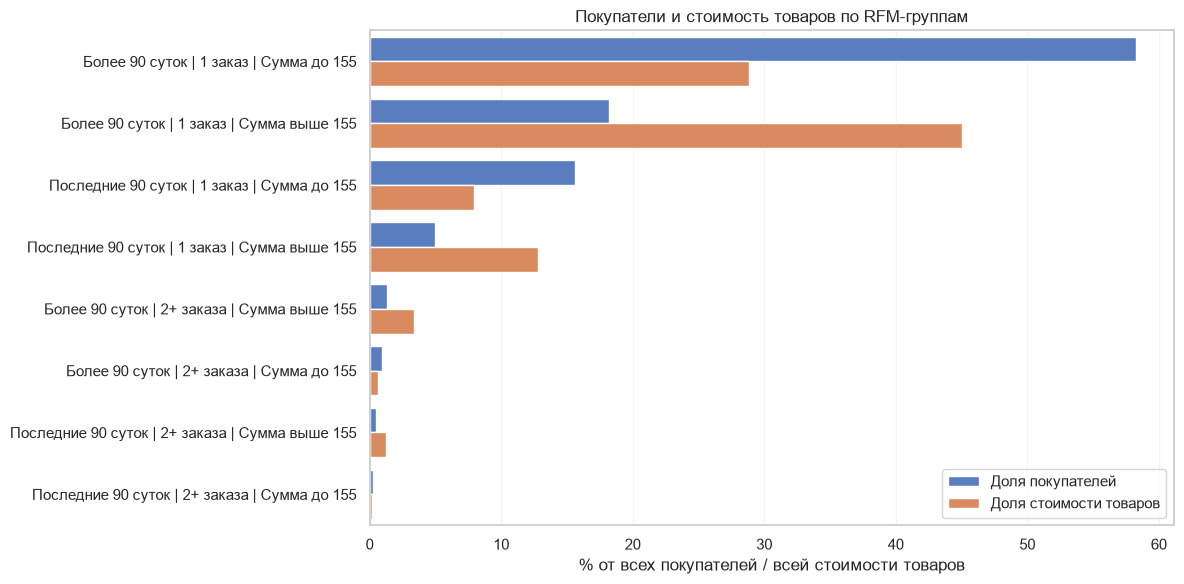

In [52]:
# Для двух столбиков на группу перевожу таблицу в длинный формат
segment_plot = segment_summary[["buyers_pct", "value_pct"]].rename(columns={
    "buyers_pct": "Доля покупателей", "value_pct": "Доля стоимости товаров"
}).reset_index()
segment_plot = segment_plot.melt(id_vars="segment", var_name="Показатель", value_name="Доля")

fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=segment_plot, x="Доля", y="segment", hue="Показатель", errorbar=None, ax=ax)
ax.set(title="Покупатели и стоимость товаров по RFM-группам", xlabel="% от всех покупателей / всей стоимости товаров", ylabel="")
ax.legend(title="", loc="lower right")

fig.tight_layout()
fig.savefig("assets/rfm_segments.png", dpi=150)
plt.show()

Покупатели с суммой товаров выше 155 BRL составляют 24,93% аудитории
и дают 62,45% стоимости. Даже один дорогой заказ может быть важен для сервиса,
поэтому одной частоты недостаточно для оценки группы.

Например, 4 310 клиентов сделали один заказ выше 155 BRL за последние 90 суток.
Эту группу можно отдельно изучить, чтобы понять опыт после крупной покупки.
Но назначать скидки или прогнозировать будущую ценность по этим расчетам рано.
Для текущей задачи доставки полезнее список конкретных заказов и направлений.

## 7. Как использовать результаты

Первым делом стоит проверить **доставку после передачи перевозчику
и обещанные сроки в SP, MG и RJ**. Рост опозданий в марте сохраняется
при разных периодах сравнения. Изменение распределения заказов между штатами
его не объясняет. Три выбранных направления дают больше половины расчетной
разницы, для них подготовлен список из 753 опоздавших заказов.

| Что проверить | Почему | За чем следить |
|---|---|---|
| Общие проблемы на маршрутах выбранных заказов после передачи перевозчику | Время после передачи выросло, увеличился P90 всего срока | P90 доставки и доля опозданий по направлению |
| Насколько реалистично обещание покупателю | Обещанный срок сократился примерно на четыре дня | Фактический срок вместе со своевременностью |
| Что считать отдельной повторной покупкой и каковы циклы покупок товаров | 32% вторых заказов сделаны в пределах суток | Повтор в одинаковом окне с явно заданным определением |

Для дальнейшего разбора сохранены [заказы](results/delivery_review.csv)
и [сравнение штатов](results/state_delay_comparison.csv).
Удлинение обещания само по себе не ускоряет доставку.
Причины различий и экономический эффект исправлений этим исследованием не установлены.

## Ограничения

Выводы относятся к доступной исторической выгрузке. Использованы итоговые
статусы заказов, состояние CRM на 1 августа не восстанавливается.
Доставка оценена среди полученных заказов с подходящими датами.
Первая наблюдаемая покупка может отличаться от первой покупки вообще.
Стоимость товаров не является доходом или прибылью платформы.
Платежи, возвраты, комиссии и затраты не исследованы.